In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
import os

In [3]:

os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 8g --executor-memory 8g pyspark-shell"

spark = SparkSession.builder \
    .appName("Colab_Optimized") \
    .master("local[*]") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.default.parallelism", "4") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .getOrCreate()

In [4]:
caminho_entrada = f'/content/drive/MyDrive/dados/amostra.csv'

In [5]:
schema_ddl  = "CD_IBGE_CADASTRO BIGINT, CO_FAMILIAR_FAM BIGINT, MARC_PBF INT, CO_CHV_NATURAL_PESSOA INT, IN_TRABALHO_INFANTIL_PESSOA BOOLEAN, CO_SEXO_PESSOA BYTE, DT_NASC_PESSOA DATE, CO_PARENTESCO_RF_PESSOA BYTE, CO_RACA_COR_PESSOA BYTE, CO_DEFICIENCIA_MEMB BOOLEAN, CO_SABE_LER_ESCREVER_MEMB BOOLEAN, IN_FREQUENTA_ESCOLA_MEMB BYTE, CO_CURSO_FREQUENTA_MEMB BYTE, CO_ANO_SERIE_FREQUENTA_MEMB BYTE, CO_CURSO_FREQ_PESSOA_MEMB BYTE, CO_ANO_SERIE_FREQUENTOU_MEMB BYTE, CO_CONCLUIU_FREQUENTOU_MEMB BOOLEAN, CO_TRABALHOU_SEMANA_MEMB BOOLEAN, CO_AGRICULTURA_TRAB_MEMB BOOLEAN, VL_REMUNER_EMPREGO_MEMB INT, VL_RENDA_BRUTA_12_MESES_MEMB INT, VL_RENDA_DOACAO_MEMB INT, VL_RENDA_APOSENT_MEMB INT, VL_RENDA_SEGURO_DESEMP_MEMB INT, VL_RENDA_PENSAO_ALIMEN_MEMB INT, VL_RENDA_OUTRAS_MEMB INT"

In [6]:
df_cad = spark.read.csv(caminho_entrada, header=True, schema=schema_ddl)

In [8]:
print(df_cad.columns)

['CD_IBGE_CADASTRO', 'CO_FAMILIAR_FAM', 'MARC_PBF', 'CO_CHV_NATURAL_PESSOA', 'IN_TRABALHO_INFANTIL_PESSOA', 'CO_SEXO_PESSOA', 'DT_NASC_PESSOA', 'CO_PARENTESCO_RF_PESSOA', 'CO_RACA_COR_PESSOA', 'CO_DEFICIENCIA_MEMB', 'CO_SABE_LER_ESCREVER_MEMB', 'IN_FREQUENTA_ESCOLA_MEMB', 'CO_CURSO_FREQUENTA_MEMB', 'CO_ANO_SERIE_FREQUENTA_MEMB', 'CO_CURSO_FREQ_PESSOA_MEMB', 'CO_ANO_SERIE_FREQUENTOU_MEMB', 'CO_CONCLUIU_FREQUENTOU_MEMB', 'CO_TRABALHOU_SEMANA_MEMB', 'CO_AGRICULTURA_TRAB_MEMB', 'VL_REMUNER_EMPREGO_MEMB', 'VL_RENDA_BRUTA_12_MESES_MEMB', 'VL_RENDA_DOACAO_MEMB', 'VL_RENDA_APOSENT_MEMB', 'VL_RENDA_SEGURO_DESEMP_MEMB', 'VL_RENDA_PENSAO_ALIMEN_MEMB', 'VL_RENDA_OUTRAS_MEMB']


In [9]:
df_cad.show()

+----------------+---------------+--------+---------------------+---------------------------+--------------+--------------+-----------------------+------------------+-------------------+-------------------------+------------------------+-----------------------+---------------------------+-------------------------+----------------------------+---------------------------+------------------------+------------------------+-----------------------+----------------------------+--------------------+---------------------+---------------------------+---------------------------+--------------------+
|CD_IBGE_CADASTRO|CO_FAMILIAR_FAM|MARC_PBF|CO_CHV_NATURAL_PESSOA|IN_TRABALHO_INFANTIL_PESSOA|CO_SEXO_PESSOA|DT_NASC_PESSOA|CO_PARENTESCO_RF_PESSOA|CO_RACA_COR_PESSOA|CO_DEFICIENCIA_MEMB|CO_SABE_LER_ESCREVER_MEMB|IN_FREQUENTA_ESCOLA_MEMB|CO_CURSO_FREQUENTA_MEMB|CO_ANO_SERIE_FREQUENTA_MEMB|CO_CURSO_FREQ_PESSOA_MEMB|CO_ANO_SERIE_FREQUENTOU_MEMB|CO_CONCLUIU_FREQUENTOU_MEMB|CO_TRABALHOU_SEMANA_MEMB|CO_AGRI

In [ ]:
#CD_IBGE_CADASTRO BIGINT, CO_FAMILIAR_FAM BIGINT, MARC_PBF INT,
#CO_CHV_NATURAL_PESSOA INT, IN_TRABALHO_INFANTIL_PESSOA BOOLEAN,
#CO_SEXO_PESSOA BYTE, DT_NASC_PESSOA DATE, CO_PARENTESCO_RF_PESSOA BYTE,
#CO_RACA_COR_PESSOA BYTE, CO_DEFICIENCIA_MEMB BOOLEAN,
#CO_SABE_LER_ESCREVER_MEMB BOOLEAN, IN_FREQUENTA_ESCOLA_MEMB BYTE,
#CO_CURSO_FREQUENTA_MEMB BYTE, CO_ANO_SERIE_FREQUENTA_MEMB BYTE,
#CO_CURSO_FREQ_PESSOA_MEMB BYTE, CO_ANO_SERIE_FREQUENTOU_MEMB BYTE,
#CO_CONCLUIU_FREQUENTOU_MEMB BOOLEAN, CO_TRABALHOU_SEMANA_MEMB BOOLEAN,
#CO_AGRICULTURA_TRAB_MEMB BOOLEAN, VL_REMUNER_EMPREGO_MEMB INT,
#VL_RENDA_BRUTA_12_MESES_MEMB INT, VL_RENDA_DOACAO_MEMB INT,
#VL_RENDA_APOSENT_MEMB INT, VL_RENDA_SEGURO_DESEMP_MEMB INT,
#VL_RENDA_PENSAO_ALIMEN_MEMB INT, VL_RENDA_OUTRAS_MEMB INT

In [40]:
from pyspark.sql import functions as F

#Calcula Idade
##meses entre a data atual e a data de nascimento da pessoa
##transformação de meses para ano e truncamento
df_idade = (
    df_cad
    .withColumn("Meses", F.months_between(F.lit("2018-12-31"), col("DT_NASC_PESSOA")))
    .withColumn("Idade", F.floor(F.col("Meses") / 12))
)

df_idade.select("DT_NASC_PESSOA", "Idade", "Meses").show(5)

+--------------+-----+------------+
|DT_NASC_PESSOA|Idade|       Meses|
+--------------+-----+------------+
|    2005-01-11|   13|167.64516129|
|    2002-06-06|   16|198.80645161|
|    1958-09-19|   60|723.38709677|
|    1981-07-11|   37|449.64516129|
|    2014-05-18|    4| 55.41935484|
+--------------+-----+------------+
only showing top 5 rows


In [41]:
#Calcula faixa etária
#crianças e adolescentes => 0 a 17
#jovens                  => 18 a 29
#adulto                  => 30 a 59
#idoso                   => >60

#cria uma coluna faixa etaria onde a condição depende das regras acima
df_faixa = df_idade.withColumn(
    "Faixa_Etaria",
    F.when(col("Idade") < 18, "Criança/Adolescente")
    .when((col("Idade") >= 18) & (col("Idade") <= 29), "Jovens")
    .when((col("Idade") >= 30) & (col("Idade") <= 59), "Adulto")
    .otherwise("Idoso")
)

df_faixa.select("DT_NASC_PESSOA", "Idade", "Faixa_Etaria").show(5)


+--------------+-----+-------------------+
|DT_NASC_PESSOA|Idade|       Faixa_Etaria|
+--------------+-----+-------------------+
|    2005-01-11|   13|Criança/Adolescente|
|    2002-06-06|   16|Criança/Adolescente|
|    1958-09-19|   60|              Idoso|
|    1981-07-11|   37|             Adulto|
|    2014-05-18|    4|Criança/Adolescente|
+--------------+-----+-------------------+
only showing top 5 rows


In [43]:
df_faixa = df_faixa.dropDuplicates().cache()
print(df_faixa.count())

7371116


In [44]:
#Proporção de indivíduos que declaram possuir trabalho remunerado em cada faixa

#agrupa por faixa etaria
#agrega colunas total (mostrando o total de cada faixa)
  #calcua a proporção (média) de pessoas que recebem remuneração por emprego (>0)
    #faz o arredondamento para 2 casas decimais
tr_remunerado_faixa = (
    df_faixa
    .groupBy("Faixa_Etaria")
    .agg(
        F.count('*').alias("total"),
        F.round(
            F.avg((F.col("VL_REMUNER_EMPREGO_MEMB") > 0).cast("int")) *100, 2
        )
        .alias("proporcao")
    )
)

tr_remunerado_faixa.show()

+-------------------+-------+---------+
|       Faixa_Etaria|  total|proporcao|
+-------------------+-------+---------+
|             Adulto|2417744|    48.11|
|Criança/Adolescente|2821337|     1.06|
|              Idoso| 695099|    10.81|
|             Jovens|1436936|    27.06|
+-------------------+-------+---------+



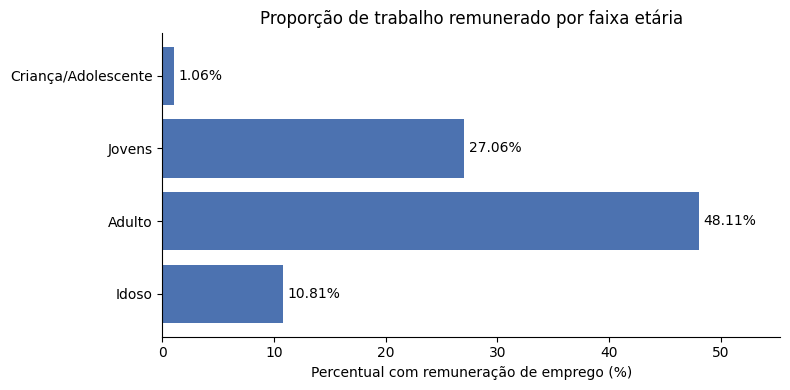

In [54]:
import matplotlib.pyplot as plt
import pandas

ordem = ["Criança/Adolescente", "Jovens", "Adulto", "Idoso"]   # ajuste para os textos da sua coluna
pdf = tr_remunerado_faixa.toPandas().set_index("Faixa_Etaria").loc[ordem].reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.barh(pdf["Faixa_Etaria"], pdf["proporcao"], color="#4C72B0")

ax.bar_label(barras, labels=[f"{v:.2f}%" for v in pdf["proporcao"]], padding=3)
ax.invert_yaxis()
ax.set_xlabel("Percentual com remuneração de emprego (%)")
ax.set_title("Proporção de trabalho remunerado por faixa etária")
ax.set_xlim(0, pdf["proporcao"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [45]:
#VL_REMUNER_EMPREGO_MEMB INT, VL_RENDA_DOACAO_MEMB INT,
#VL_RENDA_APOSENT_MEMB INT, VL_RENDA_SEGURO_DESEMP_MEMB INT,
#VL_RENDA_PENSAO_ALIMEN_MEMB INT, VL_RENDA_OUTRAS_MEMB INT

from pyspark.sql.window import Window

#salario minimio atual
SAL_MIN = 1621

#colunas relacionadas a renda
cols_renda = [
    "VL_REMUNER_EMPREGO_MEMB", "VL_RENDA_DOACAO_MEMB", "VL_RENDA_APOSENT_MEMB",
    "VL_RENDA_SEGURO_DESEMP_MEMB", "VL_RENDA_PENSAO_ALIMEN_MEMB", "VL_RENDA_OUTRAS_MEMB",
]

#para não colapsar para uma linha só, já que o interesse é separar as pessoas
#e não as familias porém precisamos que os calculos sejam para a mesma familia
w_fam = Window.partitionBy("CD_IBGE_CADASTRO", "CO_FAMILIAR_FAM")

#para não ocorrer soma com nulo, trata nulo como 0
#cria uma coluna renda_membro com a soma de todas as colunas de interesse
#cria uma coluna renda_familia com a soma de todos os membros dentro de um
  #mesmo código familiar e de município
#cria uma coluna com o números de membros dentro da familia
#cria uma coluna que divide a renda da familia pelo número de membros para des-
  #cobrir a renda per capita
#cria uma coluna que define a faixa da renda
df_renda = (
    df_cad
    .fillna(0, subset=cols_renda)
    .withColumn("renda_membro", sum(F.col(c) for c in cols_renda))
    .withColumn("renda_familia", F.sum("renda_membro").over(w_fam))
    .withColumn("n_membros", F.count("*").over(w_fam))
    .withColumn("renda_per_capita", F.col("renda_familia") / F.col("n_membros"))
    .withColumn(
        "faixa_renda",
        F.when(col("renda_per_capita") <= 218, "Até R$218,00")
         .when(col("renda_per_capita") <= SAL_MIN / 4, "Até 1/4")
         .when(col("renda_per_capita") <= SAL_MIN / 2, "de 1/4 a 1/2")
         .when(col("renda_per_capita") <= SAL_MIN, "de 1/2 a 1")
         .otherwise("Mais de 1")
    )
)



In [46]:
df_renda = df_renda.dropDuplicates().cache()
print(df_renda.count())

7371116


In [47]:
df_renda.select("renda_membro", "renda_familia", "n_membros", "renda_per_capita", "faixa_renda", "CO_DEFICIENCIA_MEMB").show(20)

+------------+-------------+---------+-----------------+------------+-------------------+
|renda_membro|renda_familia|n_membros| renda_per_capita| faixa_renda|CO_DEFICIENCIA_MEMB|
+------------+-------------+---------+-----------------+------------+-------------------+
|         100|          100|        1|            100.0|Até R$218,00|               NULL|
|           0|          937|        3|312.3333333333333|     Até 1/4|               NULL|
|           0|          937|        3|312.3333333333333|     Até 1/4|               NULL|
|         937|          937|        3|312.3333333333333|     Até 1/4|               NULL|
|           0|            0|        1|              0.0|Até R$218,00|               NULL|
|         880|          880|        1|            880.0|  de 1/2 a 1|               NULL|
|           0|            0|        1|              0.0|Até R$218,00|               NULL|
|         954|          954|        1|            954.0|  de 1/2 a 1|               NULL|
|         

In [48]:
#testar com o dataset completo

(df_renda
 .groupBy("faixa_renda")
 .agg(
     F.round(F.avg(col("CO_DEFICIENCIA_MEMB").cast("int")) * 100, 2).alias("percentual_pcd")
  )
 .show()
)


+------------+--------------+
| faixa_renda|percentual_pcd|
+------------+--------------+
|     Até 1/4|          NULL|
|de 1/4 a 1/2|          NULL|
|   Mais de 1|          NULL|
|Até R$218,00|          NULL|
|  de 1/2 a 1|          NULL|
+------------+--------------+



In [49]:
df_renda.agg(
    F.count("*").alias("total"),
    F.sum(F.col("CO_DEFICIENCIA_MEMB").isNull().cast("int")).alias("nulos"),
    F.round(F.avg(F.col("CO_DEFICIENCIA_MEMB").isNull().cast("int")) * 100, 2).alias("percentual_nulos"),
).show()

+-------+-------+----------------+
|  total|  nulos|percentual_nulos|
+-------+-------+----------------+
|7371116|7371116|           100.0|
+-------+-------+----------------+



In [21]:
#pergunta 1

#apenas linhas em que renda por emprego remunerado é maior que 0
  #cria uma coluna sexo traduzindo os valores para rotulos
  #cria uma coluna cor/raça traduzindo os valores para rotulos

df_renda_individual = (
    df_cad
    .filter(col("VL_REMUNER_EMPREGO_MEMB") > 0)
    .withColumn(
        "sexo",
        F.when(col("CO_SEXO_PESSOA") == 1, "Masculino")
        .when(col("CO_SEXO_PESSOA") == 2, "Feminino")
        .otherwise("Não informado")
    )
    .withColumn(
        "raca_cor",
        F.when(col("CO_RACA_COR_PESSOA") == 1, "Branca")
        .when(col("CO_RACA_COR_PESSOA") == 2, "Preta")
        .when(col("CO_RACA_COR_PESSOA") == 3, "Amarela")
        .when(col("CO_RACA_COR_PESSOA") == 4, "Parda")
        .when(col("CO_RACA_COR_PESSOA") == 5, "Indígena")
        .otherwise("Não informada")
    )
)

In [22]:
#com exceção do não informado, o número bruto de mulheres superam o de homens
#em todas as faixas de cor/raça. Da mesma forma, para todas as categorias nota-se
#que o valor médio em relação a renda de trabalho dos homens supera o valor médio
#das mulheres. Para raça/cor branca, em particular, a diferença da mediana entre
#eles é de R$250,00, sendo a maior, seguida dos R$100,00 para raça/cor preta.
#Destaca-se ainda que as faixas de valores mais baixos permanecem em raça/cor
#indígena.

#agrupa por raça/cor e sexo
  #cria uma coluna n contando quantos tem no agrupamento
  #calcula a media salarial com duas casas decimais
  #calcula a mediana
resumo = (
    df_renda_individual
    .groupBy("raca_cor", "sexo")
    .agg(
        F.count("*").alias("n"),
        F.round(F.avg(col("VL_REMUNER_EMPREGO_MEMB")), 2).alias("media"),
        F.percentile_approx(col("VL_REMUNER_EMPREGO_MEMB"), 0.5).alias("mediana"),
    )
)

resumo.orderBy("raca_cor", "sexo").show()

+-------------+---------+------+------+-------+
|     raca_cor|     sexo|     n| media|mediana|
+-------------+---------+------+------+-------+
|      Amarela| Feminino|  5000|533.13|    320|
|      Amarela|Masculino|  3412| 646.9|    400|
|       Branca| Feminino|244137|630.06|    450|
|       Branca|Masculino|206199|798.27|    700|
|     Indígena| Feminino|  5201|347.99|    200|
|     Indígena|Masculino|  5093|421.41|    250|
|Não informada| Feminino|   369| 654.8|    500|
|Não informada|Masculino|   467|701.54|    600|
|        Parda| Feminino|553663| 447.6|    280|
|        Parda|Masculino|469480|527.83|    300|
|        Preta| Feminino| 81939|478.53|    300|
|        Preta|Masculino| 56724|602.08|    400|
+-------------+---------+------+------+-------+



In [35]:
#pergunta 2

'''
1 - Creche
2 - Pré-escola (exceto CA)
3 - Classe de Alfabetização - CA
4 - Ensino Fundamental 1ª a 4ª séries,
Elementar (Primário), Primeira fase do 1º
grau
5 - Ensino Fundamental 5ª a 8ª séries,
Médio 1º ciclo (Ginasial), Segunda fase do
1º grau
6 - Ensino Fundamental (duração 9 anos)
7 - Ensino Fundamental Especial
8 - Ensino Médio, 2º grau, Médio 2º ciclo
(Científico, Clássico, Técnico, Normal)
9 - Ensino Médio Especial
10 - Ensino Fundamental EJA - séries
iniciais (Supletivo 1ª a 4ª)
11 - Ensino Fundamental EJA - séries
finais (Supletivo 5ª a 8ª)
12 - Ensino Médio EJA (Supletivo)
13 - Superior, Aperfeiçoamento,
Especialização, Mestrado, Doutorado
14 - Alfabetização para Adultos (Mobral,
etc.)
15 - Nenhum
'''
#creche, pré-escola, ca e alfabetização para adultos incluidos como fundamental

df_escolaridade = df_cad.withColumn(
    "escolaridade",
    F.when(col("CO_CURSO_FREQ_PESSOA_MEMB").isin(1, 2, 3, 4, 5, 6, 7, 10, 11, 14), "Fundamental")
     .when(col("CO_CURSO_FREQ_PESSOA_MEMB").isin(8, 9, 12, 14), "Médio")
     .when(col("CO_CURSO_FREQ_PESSOA_MEMB") == 13, "Superior")
     .otherwise("Sem Instrução")
)

df_escolaridade.select("CO_CURSO_FREQ_PESSOA_MEMB", "escolaridade").show(20)

+-------------------------+-------------+
|CO_CURSO_FREQ_PESSOA_MEMB| escolaridade|
+-------------------------+-------------+
|                     NULL|Sem Instrução|
|                     NULL|Sem Instrução|
|                       11|  Fundamental|
|                        4|  Fundamental|
|                     NULL|Sem Instrução|
|                     NULL|Sem Instrução|
|                     NULL|Sem Instrução|
|                        5|  Fundamental|
|                        5|  Fundamental|
|                        8|        Médio|
|                        4|  Fundamental|
|                        8|        Médio|
|                        8|        Médio|
|                     NULL|Sem Instrução|
|                     NULL|Sem Instrução|
|                        5|  Fundamental|
|                        4|  Fundamental|
|                        4|  Fundamental|
|                     NULL|Sem Instrução|
|                     NULL|Sem Instrução|
+-------------------------+-------

In [36]:
informal = (F.col("VL_RENDA_BRUTA_12_MESES_MEMB") != 0) & (F.col("VL_REMUNER_EMPREGO_MEMB") == 0)

(df_escolaridade
  .groupBy("escolaridade")
  .agg(
      F.count("*").alias("n"),
      F.sum(informal.cast("int")).alias("n_informais"),
      F.round(
          F.avg(informal.cast("int")) * 100, 2
      ).alias("percentual_informal"),
  )
).show()

+-------------+-------+-----------+-------------------+
| escolaridade|      n|n_informais|percentual_informal|
+-------------+-------+-----------+-------------------+
|Sem Instrução|3578113|       8865|               6.14|
|     Superior|  83815|       3061|               6.78|
|        Médio|1436459|      46385|               7.06|
|  Fundamental|2273469|      52004|                5.8|
+-------------+-------+-----------+-------------------+



In [27]:
#pergunta 3
df_renda = df_renda.withColumn(
    "extrema_pobreza",
    F.col("renda_per_capita") <= 89
)

chaves = ["CD_IBGE_CADASTRO", "CO_FAMILIAR_FAM", "CO_CHV_NATURAL_PESSOA"]

df_reda_faixa = df_renda.join(
    df_faixa.select(*chaves, "Faixa_Etaria"),
    on=chaves,
    how="left",
)

In [ ]:
print(df_renda.count(), df_reda_faixa.count())
print(df_reda_faixa.filter(F.col("Faixa_Etaria").isNull()).count())

7371116 7371116
0


In [28]:
#agrupa por faixa etaria
  #conta o total de pessoas por faixa
  #soma o numero de pessoas pcd nessas faixas
  #cria uma coluna para ver a média percentual de pessoas
    #pcd na faixa
  #cria uma coluna para ver a média percentual de pessoas
    #pcd na extrema pobreza


resultado3 = (
    df_reda_faixa
    .groupBy("Faixa_Etaria")
    .agg(
        F.count("*").alias("total"),
        F.sum(F.col("CO_DEFICIENCIA_MEMB").cast("int")).alias("n_pcd"),
        F.round(
            F.avg(F.col("CO_DEFICIENCIA_MEMB").cast("int")) * 100, 2
        ).alias("percentual_pcd"),
        F.round(
            F.avg(F.when(F.col("CO_DEFICIENCIA_MEMB") == True,
                         F.col("extrema_pobreza").cast("int"))) * 100, 2
        ).alias("percentual_pcd_extrema_pobreza"),
        F.round(
            F.avg(F.col("extrema_pobreza").cast("int")) * 100, 2
        ).alias("percentual_extrema_pobreza"),
    )
)

resultado3.show()

+-------------------+-------+-----+--------------+------------------------------+--------------------------+
|       Faixa_Etaria|  total|n_pcd|percentual_pcd|percentual_pcd_extrema_pobreza|percentual_extrema_pobreza|
+-------------------+-------+-----+--------------+------------------------------+--------------------------+
|             Adulto|2796575| NULL|          NULL|                          NULL|                     44.81|
|Criança/Adolescente|1542393| NULL|          NULL|                          NULL|                     88.92|
|              Idoso|1142995| NULL|          NULL|                          NULL|                     26.51|
|             Jovens|1889153| NULL|          NULL|                          NULL|                      83.8|
+-------------------+-------+-----+--------------+------------------------------+--------------------------+



In [39]:
print(df_idade.filter(F.col("Idade").between(6, 10)).count())

405508


In [50]:
#pergunta 4

df_fam_criança = df_idade.withColumn(
    "tem_crianca_0_6",
    F.max(F.col("Idade").between(0, 6).cast("int")).over(w_fam) == 1
)

#sexo==2 feminino, parentesco ==1 é responsável pela unidade familiar
#agrupa por tem criança
#conta a quantidade e calcula a media das mulheres que possuem emprego
#remunerado
(df_fam_criança
 .filter(
     (F.col("CO_SEXO_PESSOA") == 2) & (F.col("CO_PARENTESCO_RF_PESSOA") == 1)
  )
 .groupBy("tem_crianca_0_6")
 .agg(
     F.count("*").alias("n"),
     F.round(
         F.avg((F.col("VL_REMUNER_EMPREGO_MEMB") > 0).cast("int")) * 100, 2
      ).alias("taxa_ocupacao"),
 )
 .show())

+---------------+-------+-------------+
|tem_crianca_0_6|      n|taxa_ocupacao|
+---------------+-------+-------------+
|          false|2139650|        36.31|
|           true|  94769|        37.21|
+---------------+-------+-------------+



In [7]:
import pandas

data = df_cad.toPandas()

In [14]:
data.to_csv("/content/amostra_pandas.csv", index=False)

In [15]:
from google.colab import files
files.download("/content/amostra_pandas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
import pandas

#data = pandas.read_csv("part-00001-5a73ee5c-9f17-44d8-8009-a6d6f94bdb1a-c000.csv", delimiter=',')
data = df_cad.toPandas()

# 1.1 Agrupamento por gênero e cor
data["DT_NASC_PESSOA"] = pandas.to_datetime(data["DT_NASC_PESSOA"])

hoje = pandas.Timestamp("2026-10-13")

data["IDADE"] = hoje.year - data["DT_NASC_PESSOA"].dt.year

data_per_genero = data.groupby("CO_SEXO_PESSOA")["IDADE"]
data_per_cor = data.groupby("CO_RACA_COR_PESSOA")["IDADE"]

nomes_sexo = {
    1: "Masculino",
    2: "Feminino"
}

nomes_cor = {
    1: "Branca",
    2: "Preta",
    3: "Amarela",
    4: "Parda",
    5: "Indígena"
}

media_genero = data_per_genero.mean()
media_genero.index = media_genero.index.map(nomes_sexo)

mediana_genero = data_per_genero.median()
mediana_genero.index = mediana_genero.index.map(nomes_sexo)

desvio_genero = data_per_genero.std()
desvio_genero.index = desvio_genero.index.map(nomes_sexo)

media_cor = data_per_cor.mean()
media_cor.index = media_cor.index.map(nomes_cor)

mediana_cor = data_per_cor.median()
mediana_cor.index = mediana_cor.index.map(nomes_cor)

desvio_cor = data_per_cor.std()
desvio_cor.index = desvio_cor.index.map(nomes_cor)

# Usei IA para embelezar o print
print(f"""
{'=' * 52}
              ESTATÍSTICAS DE IDADE
{'=' * 52}

{'-' * 52}
  AGRUPAMENTO POR GÊNERO
{'-' * 52}
Média:
{media_genero.to_string(float_format=lambda x: f'{x:.2f}')}

Mediana:
{mediana_genero.to_string(float_format=lambda x: f'{x:.2f}')}

Desvio padrão:
{desvio_genero.to_string(float_format=lambda x: f'{x:.2f}')}

{'-' * 52}
  AGRUPAMENTO POR COR/RAÇA
{'-' * 52}
Média:
{media_cor.to_string(float_format=lambda x: f'{x:.2f}')}

Mediana:
{mediana_cor.to_string(float_format=lambda x: f'{x:.2f}')}

Desvio padrão:
{desvio_cor.to_string(float_format=lambda x: f'{x:.2f}')}

{'=' * 52}
""")

# 1.2 Trabalhadores formais e informais

data_idade_ativa = data[(data["DT_NASC_PESSOA"] <= pandas.to_datetime("2008-01-01")) & (data["DT_NASC_PESSOA"] >= pandas.to_datetime("1961-01-01"))]
"renda informal: renda bruta diferente de zero e renda por emprego = 0"
data_idade_ativa_formal = data_idade_ativa[data_idade_ativa["CO_TRABALHOU_SEMANA_MEMB"] == 1]
data_idade_ativa_informal = data_idade_ativa[(data_idade_ativa["VL_REMUNER_EMPREGO_MEMB"] == 0) & (data_idade_ativa["VL_RENDA_BRUTA_12_MESES_MEMB"] != 0)]

total_idade_ativa = data_idade_ativa.shape[0]
total_formais = data_idade_ativa_formal.shape[0]
total_informais = data_idade_ativa_informal.shape[0]

taxa_formais = total_formais / total_idade_ativa * 100
taxa_informais = total_informais / total_idade_ativa * 100

print(f"""
{'=' * 48}
       TRABALHADORES EM IDADE ATIVA
{'=' * 48}
Total de pessoas:       {total_idade_ativa:>10,}

Trabalhadores formais:  {total_formais:>10,} ({taxa_formais:>6.2f}%)
Trabalhadores informais:{total_informais:>10,} ({taxa_informais:>6.2f}%)
{'=' * 48}
""")

# 1.3 renda média por nível de escolaridade

data_renda_escolaridade = data.groupby("CO_CURSO_FREQUENTA_MEMB")["VL_RENDA_BRUTA_12_MESES_MEMB"].mean()
# 1.3 Renda média por nível de escolaridade

nomes_cursos = {
    1: "Creche",
    2: "Pré-escola",
    3: "Classe de Alfabetização",
    4: "Ensino Fundamental regular (8 anos)",
    5: "Ensino Fundamental regular (9 anos)",
    6: "Ensino Fundamental especial",
    7: "Ensino Médio regular",
    8: "Ensino Médio especial",
    9: "Ensino Fundamental EJA (séries iniciais)",
    10: "Ensino Fundamental EJA (séries finais)",
    11: "Ensino Médio EJA",
    12: "Alfabetização para adultos",
    13: "Ensino Superior",
    14: "Pré-vestibular"
}

data_renda_escolaridade = (
    data.groupby("CO_CURSO_FREQUENTA_MEMB")["VL_RENDA_BRUTA_12_MESES_MEMB"]
    .mean()
)

data_renda_escolaridade.index = (
    data_renda_escolaridade.index.map(nomes_cursos)
)

print(f"""
{'=' * 65}
             RENDA MÉDIA POR CURSO FREQUENTADO
{'=' * 65}
{data_renda_escolaridade.to_string(
    float_format=lambda x: f"R$ {x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
)}
{'=' * 65}
""")


# 3. Proposta de enriquecimento de Dados.

"""
IDEB

A escolha se deu porque os dados do IDEB são uma forma de avaliar a educação básica no Brasil, assunto de interesse para nós e de ampla importância à sociedade. Assim, esse trabalho mantém o tema de educação que escolhemos no último.

Vou fazer a ligação mapeando CD_IBGE_CADASTRO com os dados do IDEB, que utilizam o mesmo código de município.

Cidades com renda familiar média mais baixa possuem menor IDEB? Qual a relação da renda familiar média com o IDEB?

A taxa de aprovação de uma cidade tem alguma relação com a renda familiar média? E com a cor das pessoas na cidade?
"""

# Leitura dos dados do IDEB
ideb_data = pandas.read_excel(
    "divulgacao_anos_iniciais_municipios_2025.xlsx",
    usecols="B:D,BB:BG,DR",
    na_values=["-"],
    skiprows=10,
    header=None)

colunas_aprovacao = [
    "aprovacao_1_5_ano",
    "aprovacao_1_ano",
    "aprovacao_2_ano",
    "aprovacao_3_ano",
    "aprovacao_4_ano",
    "aprovacao_5_ano"
]

ideb_data.columns = [
    "codigo",
    "municipio",
    "rede",
    *colunas_aprovacao,
    "ideb_2019"
]

# Cálculo da renda média e mapeamento com os dados do CadUnico
renda_media_municipio = data.groupby("CD_IBGE_CADASTRO")["VL_RENDA_BRUTA_12_MESES_MEMB"].mean().reset_index()
renda_media_municipio = renda_media_municipio.rename(columns={
    "CD_IBGE_CADASTRO": "codigo",
    "VL_RENDA_BRUTA_12_MESES_MEMB": "renda_media"
})

renda_por_ideb = ideb_data.merge(
    renda_media_municipio,
    on="codigo",
    how="left"
)

# Cálculo da distribuição racial
distribuicao_racial = pandas.crosstab(
    data["CD_IBGE_CADASTRO"],
    data["CO_RACA_COR_PESSOA"],
    normalize="index"
) * 100

distribuicao_racial = distribuicao_racial.reset_index()

colunas_raciais = {
    1: "branca",
    2: "preta",
    3: "amarela",
    4: "parda",
    5: "indigena"
}

distribuicao_racial = distribuicao_racial.rename(columns={
    "CD_IBGE_CADASTRO": "codigo",
    **colunas_raciais,
})

renda_por_ideb_por_cor = renda_por_ideb.merge(distribuicao_racial, on="codigo", how="left")

# Prints da correlação entre renda média e IDEB

cor = renda_por_ideb["renda_media"].corr(
    renda_por_ideb["ideb_2019"],
    method="pearson"
)

print(f"Correlação entre renda média na cidade e IDEB: {cor:.3f}")

# Prints da correlação entre renda média e aprovação, e entre aprovação e distribuição racial

print("=" * 52)
for coluna in colunas_aprovacao:
    dados_validos = renda_por_ideb[["renda_media", coluna]].dropna()

    correlacao = dados_validos["renda_media"].corr(
        dados_validos[coluna],
        method="pearson"
    )

    print(f"{coluna}: {correlacao:.3f}")

print("=" * 52)
for coluna in colunas_raciais.values():
    dados_validos = renda_por_ideb_por_cor[[coluna, "aprovacao_1_5_ano"]].dropna()

    correlacao = dados_validos[coluna].corr(
        dados_validos["aprovacao_1_5_ano"],
        method="pearson"
    )

    print(f"{coluna}: {correlacao:.3f}")

OutOfBoundsDatetime: Out of bounds nanosecond timestamp: 0011-08-07, at position 1871719